# 01. Аналіз даних і підготовка

## 0. Налаштування

In [35]:
import json
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from sklearn.cluster import KMeans

SEED = 42
rng = np.random.default_rng(SEED)

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
ORIG_CLASSES = ["ignored", "pedestrian", "people", "bicycle", "car", "van", "truck", "tricycle", "awning-tricycle", "bus", "motor", "others"]
COLORS = plt.get_cmap("tab10").colors

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(20)

polars.config.Config

In [36]:
ROOT = next(
    path.parent
    for pattern in ["*/test_images.csv", "*/*/test_images.csv", "*/*/*/test_images.csv"]
    for path in Path("/kaggle/input").glob(pattern)
)
OUT = Path("/kaggle/working")
print(ROOT)
print(sorted(path.name for path in ROOT.iterdir()))

/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
['test', 'test_images.csv', 'train', 'val']


## 1. Анотації

Беремо `annotations_coco.json`, бо там рамки вже в пікселях і є `track_id`, `occlusion`, `orig_category_id`. У COCO класи нумеруються з 1, а в YOLO і в сабміті з 0, тому робимо `cls = category_id - 1`. Записи з `iscrowd = 1` це ignored regions, їх кладемо окремо.

In [37]:
def load_coco(split):
    coco = json.loads((ROOT / split / "annotations_coco.json").read_text())
    images = (
        pl.DataFrame(coco["images"], infer_schema_length=None)
        .rename({"id": "image_id"})
        .with_columns(split=pl.lit(split))
    )
    anns = pl.DataFrame(
        [
            {key: value for key, value in ann.items() if key not in ("bbox", "segmentation")}
            | dict(zip(["x", "y", "w", "h"], map(float, ann["bbox"])))
            for ann in coco["annotations"]
        ],
        infer_schema_length=None,
    )
    anns = anns.join(images.select("image_id", "video", "frame_id", "width", "height", "split"), on="image_id")
    return images, anns


loaded = [load_coco(split) for split in ["train", "val"]]
images = pl.concat([images for images, anns in loaded], how="diagonal_relaxed")
anns = pl.concat([anns for images, anns in loaded], how="diagonal_relaxed")

objects = (
    anns.filter(pl.col("iscrowd") == 0)
    .with_columns(
        cls=pl.col("category_id") - 1,
        side=(pl.col("w") * pl.col("h")).sqrt(),
        area=pl.col("w") * pl.col("h"),
    )
    .with_columns(name=pl.col("cls").replace_strict(dict(enumerate(CLASSES))))
)
ignore = anns.filter(pl.col("iscrowd") == 1)

objects.head()

id,image_id,category_id,area,iscrowd,truncation,occlusion,track_id,orig_category_id,x,…,h,ignore,video,frame_id,width,height,split,cls,side,name
i64,i64,i64,f64,i64,i64,i64,i64,i64,f64,…,f64,i64,str,i64,i64,i64,str,i64,f64,str
1,1,1,3080.0,0,0,0,2,1,424.0,…,88.0,null,"""uav0000013_00000_v""",1,1344,756,"""train""",0,55.497748,"""person"""
2,1,1,3060.0,0,0,1,3,1,416.0,…,85.0,null,"""uav0000013_00000_v""",1,1344,756,"""train""",0,55.317267,"""person"""
3,1,6,9918.0,0,1,0,4,7,531.0,…,114.0,null,"""uav0000013_00000_v""",1,1344,756,"""train""",5,99.589156,"""tricycle"""
4,1,1,2528.0,0,0,0,5,1,591.0,…,79.0,null,"""uav0000013_00000_v""",1,1344,756,"""train""",0,50.27922,"""person"""
5,1,1,1008.0,0,0,0,6,1,454.0,…,48.0,null,"""uav0000013_00000_v""",1,1344,756,"""train""",0,31.749016,"""person"""


Порівнюємо з описом змагання: 56 і 7 кліпів, 24 201 і 2 846 кадрів.

In [38]:
summary = (
    images.group_by("split")
    .agg(clips=pl.col("video").n_unique(), frames=pl.len())
    .join(objects.group_by("split").agg(objects=pl.len()), on="split")
    .join(ignore.group_by("split").agg(ignore_regions=pl.len()), on="split", how="left")
    .with_columns(objects_per_frame=(pl.col("objects") / pl.col("frames")).round(1))
    .sort("split", descending=True)
)
summary

split,clips,frames,objects,ignore_regions,objects_per_frame
str,u32,u32,u32,u32,f64
"""val""",7,2846,114132,31960,40.1
"""train""",56,24201,1105516,510744,45.7


### 1.1 Якість розмітки

Перед тренуванням перевіряємо, чи немає зламаних рамок: нульового розміру, менших за 2 px, з виходом за межі кадру, повторів у тому самому кадрі і рамок з дуже дивними пропорціями.

In [39]:
objects.group_by("split").agg(
    total=pl.len(),
    zero_size=((pl.col("w") <= 0) | (pl.col("h") <= 0)).sum(),
    smaller_than_2px=((pl.col("w") < 2) | (pl.col("h") < 2)).sum(),
    outside_frame=((pl.col("x") < 0) | (pl.col("y") < 0) | (pl.col("x") + pl.col("w") > pl.col("width")) | (pl.col("y") + pl.col("h") > pl.col("height"))).sum(),
    duplicated=pl.struct("split", "image_id", "cls", "x", "y", "w", "h").is_duplicated().sum(),
    aspect_over_10=((pl.col("w") / pl.col("h") > 10) | (pl.col("h") / pl.col("w") > 10)).sum(),
    no_track_id=pl.col("track_id").is_null().sum(),
)

split,total,zero_size,smaller_than_2px,outside_frame,duplicated,aspect_over_10,no_track_id
str,u32,u32,u32,u32,u32,u32,u32
"""train""",1105516,0,0,0,0,102,0
"""val""",114132,0,0,0,0,26,0


## 2. Перевірка YOLO і COCO

YOLO зберігає центр і розмір рамки в частках від кадру, а COCO і сабміт хочуть лівий верхній кут у пікселях. Пишемо переклад з YOLO в пікселі (він знадобиться і для сабміту) і звіряємо з COCO на 50 випадкових кадрах.

In [40]:
def yolo_to_pixels(path, width, height):
    if not path.exists() or path.stat().st_size == 0:
        return np.zeros((0, 5))
    rows = np.loadtxt(path, ndmin=2)
    cx, cy, w, h = (rows[:, -4:] * [width, height, width, height]).T
    cls = rows[:, 0] if rows.shape[1] == 5 else np.full(len(rows), -1.0)
    return np.column_stack([cls, cx - w / 2, cy - h / 2, w, h])


def frame_path(split, file_name, folder="images", suffix=".jpg"):
    base = ROOT / split if (ROOT / split / file_name).exists() else ROOT
    return (base / file_name).with_suffix(suffix).as_posix().replace("/images/", f"/{folder}/")


def sort_boxes(boxes):
    return boxes[np.lexsort(np.round(boxes[:, ::-1], 1).T)]


checks = []
for row in images.sample(50, seed=SEED).iter_rows(named=True):
    from_yolo = yolo_to_pixels(Path(frame_path(row["split"], row["file_name"], "labels", ".txt")), row["width"], row["height"])
    from_coco = objects.filter(pl.col("image_id") == row["image_id"], pl.col("split") == row["split"]).select("cls", "x", "y", "w", "h").to_numpy()
    same_count = len(from_yolo) == len(from_coco)
    max_diff = float(np.abs(sort_boxes(from_yolo) - sort_boxes(from_coco)).max()) if same_count and len(from_coco) else 0.0
    checks.append({"video": row["video"], "frame_id": row["frame_id"], "same_count": same_count, "max_diff_px": round(max_diff, 3)})

checks = pl.DataFrame(checks)
print("кадрів з різною кількістю рамок:", checks.filter(~pl.col("same_count")).height)
print("максимальна різниця координат, px:", checks["max_diff_px"].max())

кадрів з різною кількістю рамок: 0
максимальна різниця координат, px: 0.003


Те саме, але очима: рамки з YOLO-файлів і заштриховані ignored regions. Три найщільніші кадри і три випадкові з інших відео.

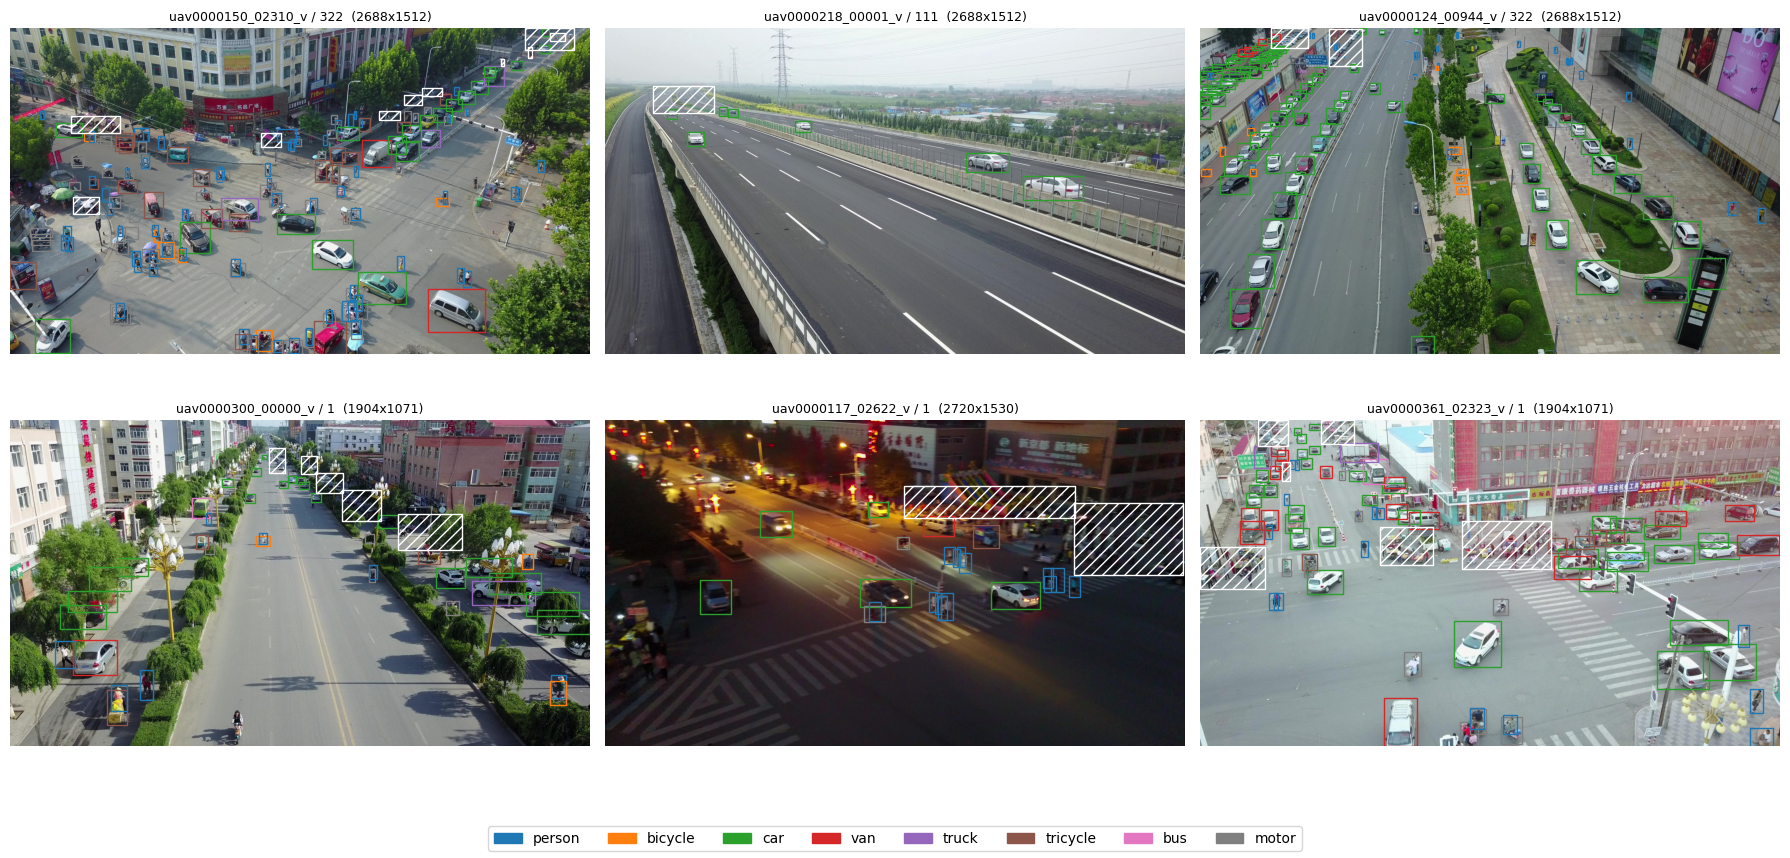

In [41]:
def draw_frame(ax, row, show_ignore=True):
    image = Image.open(frame_path(row["split"], row["file_name"]))
    ax.imshow(image)
    for cls, x, y, w, h in yolo_to_pixels(Path(frame_path(row["split"], row["file_name"], "labels", ".txt")), row["width"], row["height"]):
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, ec=COLORS[int(cls)], lw=1))
    if show_ignore:
        for cls, x, y, w, h in yolo_to_pixels(Path(frame_path(row["split"], row["file_name"], "ignore", ".txt")), row["width"], row["height"]):
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, ec="white", hatch="///", lw=1))
    ax.set_title(f"{row['video']} / {row['frame_id']}  ({row['width']}x{row['height']})", fontsize=9)
    ax.axis("off")


per_frame = objects.group_by("split", "image_id").agg(n=pl.len())
busiest = images.join(per_frame, on=["split", "image_id"]).sort("n", descending=True).unique("video", keep="first").head(3)
random_frames = images.filter(~pl.col("video").is_in(busiest["video"].to_list())).unique("video").sample(3, seed=SEED)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, row in zip(axes.flat, pl.concat([busiest.drop("n"), random_frames]).iter_rows(named=True)):
    draw_frame(ax, row)
handles = [patches.Patch(color=COLORS[i], label=name) for i, name in enumerate(CLASSES)]
fig.legend(handles=handles, loc="lower center", ncol=8)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

Збільшуємо шматок кадру, бо дрібні рамки на повному кадрі майже не видно.

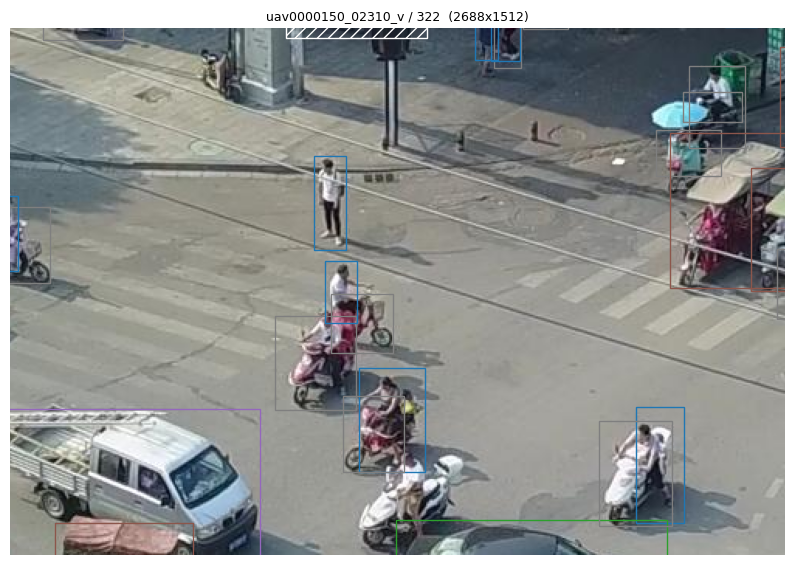

In [42]:
row = busiest.row(0, named=True)
boxes = objects.filter(pl.col("image_id") == row["image_id"], pl.col("split") == row["split"])
cx, cy = boxes["x"].median(), boxes["y"].median()

fig, ax = plt.subplots(figsize=(10, 7))
draw_frame(ax, row)
ax.set_xlim(cx - 250, cx + 250)
ax.set_ylim(cy + 170, cy - 170)
plt.show()

## 3. Класи

### 3.1 Скільки об'єктів кожного класу

In [43]:
class_counts = (
    objects.group_by("split", "name")
    .agg(count=pl.len())
    .with_columns(share=(pl.col("count") / pl.col("count").sum().over("split") * 100).round(2))
)
class_counts.pivot(on="split", index="name", values=["count", "share"]).sort("count_train", descending=True)

name,count_train,count_val,share_train,share_val
str,u32,u32,f64,f64
"""car""",505301,31821,45.71,27.88
"""person""",328701,50312,29.73,44.08
"""motor""",102819,12025,9.3,10.54
"""van""",46940,6842,4.25,5.99
"""tricycle""",41349,5487,3.74,4.81
"""bicycle""",40255,6022,3.64,5.28
"""truck""",30498,1359,2.76,1.19
"""bus""",9653,264,0.87,0.23


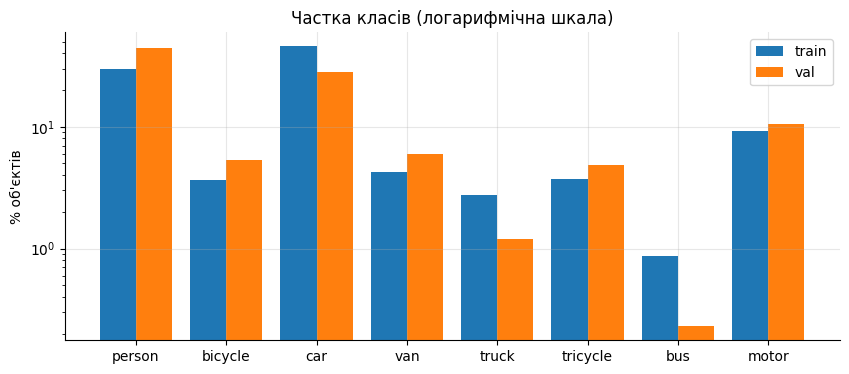

In [44]:
fig, ax = plt.subplots(figsize=(10, 4))
for offset, split in [(-0.2, "train"), (0.2, "val")]:
    shares = class_counts.filter(pl.col("split") == split)
    order = [shares.filter(pl.col("name") == name)["share"].item() for name in CLASSES]
    ax.bar(np.arange(len(CLASSES)) + offset, order, width=0.4, label=split)
ax.set_xticks(range(len(CLASSES)), CLASSES)
ax.set_ylabel("% об'єктів")
ax.set_yscale("log")
ax.set_title("Частка класів (логарифмічна шкала)")
ax.legend()
plt.show()

### 3.2 Звідки 8 класів

В оригінальному VisDrone було 10 класів плюс `ignored` і `others`. Дивимось через `orig_category_id`, що з чим об'єднали.

In [45]:
(
    anns.with_columns(orig=pl.col("orig_category_id").replace_strict(dict(enumerate(ORIG_CLASSES)), default="?"))
    .with_columns(target=pl.when(pl.col("iscrowd") == 1).then(pl.lit("ignore region")).otherwise((pl.col("category_id") - 1).replace_strict(dict(enumerate(CLASSES)), default="?")))
    .group_by("orig", "target")
    .agg(count=pl.len())
    .sort("count", descending=True)
)

orig,target,count
str,str,u32
"""car""","""car""",537122
"""ignored""","""ignore region""",530904
"""pedestrian""","""person""",266709
"""motor""","""motor""",114844
"""people""","""person""",112304
"""van""","""van""",53782
"""bicycle""","""bicycle""",46277
"""tricycle""","""tricycle""",32107
"""truck""","""truck""",31857


### 3.3 Склад класів у різних відео

Якщо відео сильно відрізняються за класами, то оцінка буде дуже залежати від того, які відео потрапили у val.

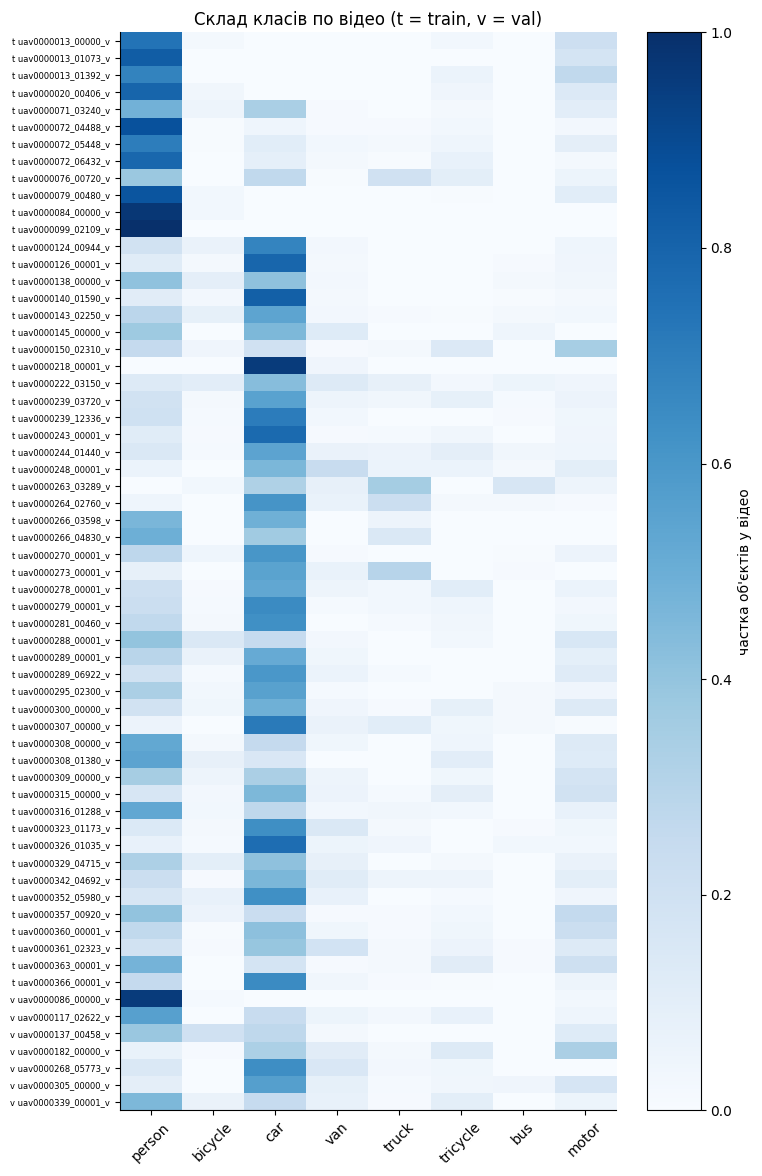

In [46]:
clip_classes = (
    objects.group_by("split", "video", "name")
    .agg(count=pl.len())
    .with_columns(share=pl.col("count") / pl.col("count").sum().over("video"))
    .pivot(on="name", index=["split", "video"], values="share")
    .fill_null(0)
    .sort("split", "video")
)
matrix = clip_classes.select([name for name in CLASSES if name in clip_classes.columns]).to_numpy()

fig, ax = plt.subplots(figsize=(8, 14))
image = ax.imshow(matrix, aspect="auto", cmap="Blues")
ax.set_xticks(range(matrix.shape[1]), [name for name in CLASSES if name in clip_classes.columns], rotation=45)
ax.set_yticks(range(len(clip_classes)), [f"{split[:1]} {video}" for split, video in clip_classes.select("split", "video").iter_rows()], fontsize=6)
ax.grid(False)
plt.colorbar(image, ax=ax, label="частка об'єктів у відео")
ax.set_title("Склад класів по відео (t = train, v = val)")
plt.show()

## 4. Розміри об'єктів

Пороги COCO: small це площа менше 32², medium до 96², large більше. За ними рахується AP_small. Розмір рахуємо як `sqrt(w*h)`.

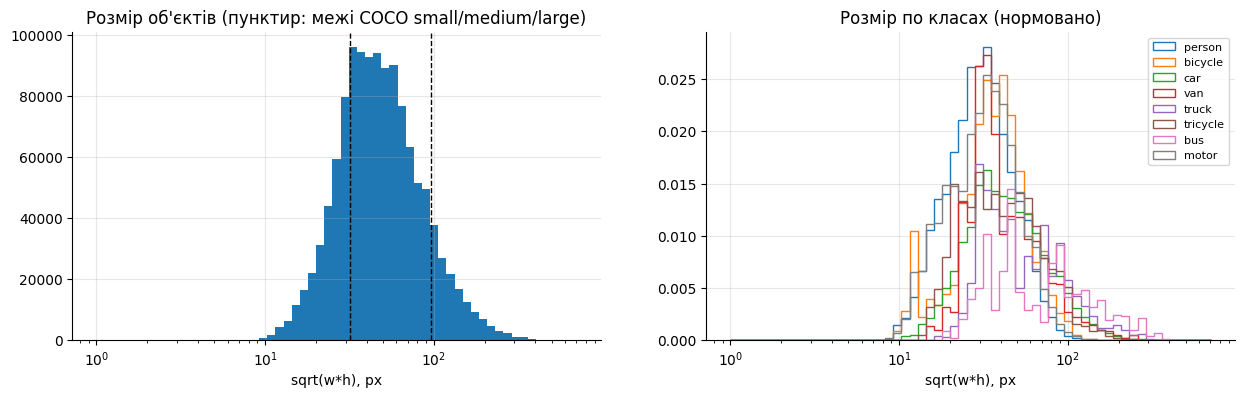

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
bins = np.logspace(0, np.log10(objects["side"].max() + 1), 60)
axes[0].hist(objects["side"], bins=bins, color=COLORS[0])
for edge in (32, 96):
    axes[0].axvline(edge, color="k", ls="--", lw=1)
axes[0].set_xscale("log")
axes[0].set_xlabel("sqrt(w*h), px")
axes[0].set_title("Розмір об'єктів (пунктир: межі COCO small/medium/large)")

for i, name in enumerate(CLASSES):
    sides = objects.filter(pl.col("name") == name)["side"]
    axes[1].hist(sides, bins=bins, histtype="step", density=True, color=COLORS[i], label=name, lw=1.5)
axes[1].set_xscale("log")
axes[1].set_xlabel("sqrt(w*h), px")
axes[1].set_title("Розмір по класах (нормовано)")
axes[1].legend(fontsize=8)
plt.show()

In [48]:
(
    objects.with_columns(
        bucket=pl.when(pl.col("area") < 32**2).then(pl.lit("small")).when(pl.col("area") < 96**2).then(pl.lit("medium")).otherwise(pl.lit("large"))
    )
    .group_by("name", "bucket")
    .agg(count=pl.len())
    .with_columns(share=(pl.col("count") / pl.col("count").sum().over("name") * 100).round(1))
    .pivot(on="bucket", index="name", values="share")
    .join(objects.group_by("name").agg(median_side=pl.col("side").median().round(1), count=pl.len()), on="name")
    .sort("count", descending=True)
)

name,medium,large,small,median_side,count
str,f64,f64,f64,f64,u32
"""car""",64.9,19.2,15.9,57.5,537122
"""person""",61.7,0.7,37.5,36.7,379013
"""motor""",66.8,1.7,31.4,39.8,114844
"""van""",63.8,16.7,19.4,51.3,53782
"""tricycle""",65.3,14.0,20.7,54.5,46836
"""bicycle""",75.6,2.8,21.6,43.9,46277
"""truck""",57.5,33.4,9.1,73.9,31857
"""bus""",39.3,56.7,4.0,111.7,9917


### 4.1 Що буде після resize

Ultralytics за замовчуванням стискає довшу сторону кадру до 640 px, тож кадр 1920 px стиснеться втричі. Найдрібніша сітка YOLO має крок 8 px, і об'єкт менший за 8 px займає менше однієї клітинки. Рахуємо, скільки таких об'єктів буде при різних `imgsz`.

In [49]:
resize_table = pl.DataFrame(
    [
        {
            "imgsz": size,
            "< 8 px, %": round(objects.select(((pl.col("side") * size / pl.max_horizontal("width", "height")) < 8).mean()).item() * 100, 1),
            "< 16 px, %": round(objects.select(((pl.col("side") * size / pl.max_horizontal("width", "height")) < 16).mean()).item() * 100, 1),
            "COCO small після resize, %": round(objects.select(((pl.col("side") * size / pl.max_horizontal("width", "height")) < 32).mean()).item() * 100, 1),
        }
        for size in [640, 960, 1280, 1536, 1920]
    ]
)
resize_table

imgsz,"< 8 px, %","< 16 px, %","COCO small після resize, %"
i64,f64,f64,f64
640,9.7,53.6,89.2
960,1.8,23.5,73.2
1280,0.6,9.7,53.6
1536,0.2,4.8,39.4
1920,0.0,1.8,23.5


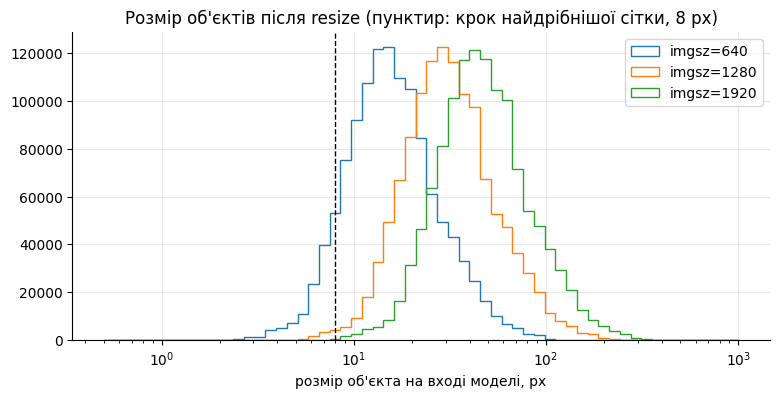

In [50]:
fig, ax = plt.subplots(figsize=(9, 4))
for size in [640, 1280, 1920]:
    scaled = objects.select(pl.col("side") * size / pl.max_horizontal("width", "height")).to_series()
    ax.hist(scaled, bins=np.logspace(-0.3, 3, 60), histtype="step", lw=1.5, label=f"imgsz={size}")
ax.axvline(8, color="k", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("розмір об'єкта на вході моделі, px")
ax.set_title("Розмір об'єктів після resize (пунктир: крок найдрібнішої сітки, 8 px)")
ax.legend()
plt.show()

### 4.2 Пропорції рамок і anchors

У torchvision найменший anchor за замовчуванням 32 px. Перевіряємо, чи це взагалі підходить нашим даним. Спершу пропорції w/h по класах.

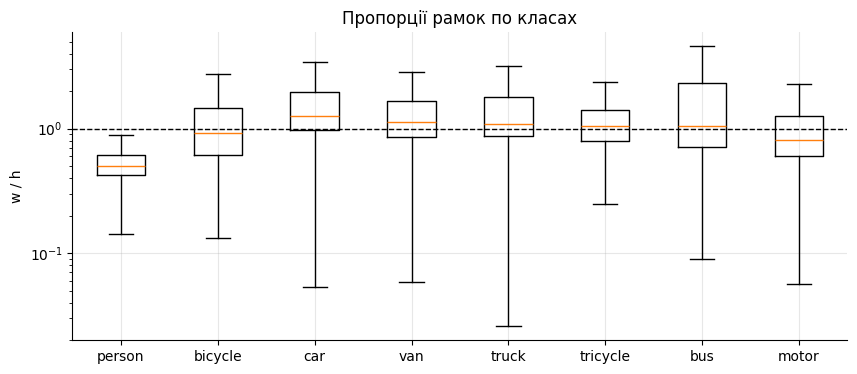

In [51]:
fig, ax = plt.subplots(figsize=(10, 4))
ratios = [objects.filter(pl.col("name") == name).select(pl.col("w") / pl.col("h")).to_series().to_numpy() for name in CLASSES]
ax.boxplot(ratios, showfliers=False)
ax.set_xticks(range(1, len(CLASSES) + 1), CLASSES)
ax.set_yscale("log")
ax.axhline(1, color="k", ls="--", lw=1)
ax.set_ylabel("w / h")
ax.set_title("Пропорції рамок по класах")
plt.show()

k-means по (w, h) на 9 кластерів, як у YOLOv2. Рахуємо в пікселях після resize до 1280, бо anchors задаються вже на вході моделі. 1280 тут поки робоче припущення.

In [52]:
ANCHOR_IMGSZ = 1280
wh = (
    objects.sample(min(200_000, objects.height), seed=SEED)
    .select(
        (pl.col("w") * ANCHOR_IMGSZ / pl.max_horizontal("width", "height")).alias("w"),
        (pl.col("h") * ANCHOR_IMGSZ / pl.max_horizontal("width", "height")).alias("h"),
    )
    .to_numpy()
)
kmeans = KMeans(n_clusters=9, random_state=SEED, n_init=10).fit(wh)
centers = kmeans.cluster_centers_[np.argsort(kmeans.cluster_centers_.prod(axis=1))]

pl.DataFrame(
    {
        "w": centers[:, 0].round(1),
        "h": centers[:, 1].round(1),
        "sqrt(w*h)": np.sqrt(centers.prod(axis=1)).round(1),
        "w/h": (centers[:, 0] / centers[:, 1]).round(2),
        "share of boxes, %": (np.bincount(kmeans.labels_, minlength=9)[np.argsort(kmeans.cluster_centers_.prod(axis=1))] / len(wh) * 100).round(1),
    }
)

w,h,sqrt(w*h),w/h,"share of boxes, %"
f64,f64,f64,f64,f64
16.8,19.3,18.0,0.87,27.3
21.7,35.4,27.7,0.61,22.1
42.7,27.6,34.4,1.54,18.6
35.1,55.3,44.0,0.63,12.3
74.7,40.9,55.3,1.83,8.8
59.8,85.6,71.6,0.7,4.8
120.4,62.1,86.5,1.94,4.1
109.0,130.2,119.1,0.84,1.3
210.9,117.8,157.6,1.79,0.8


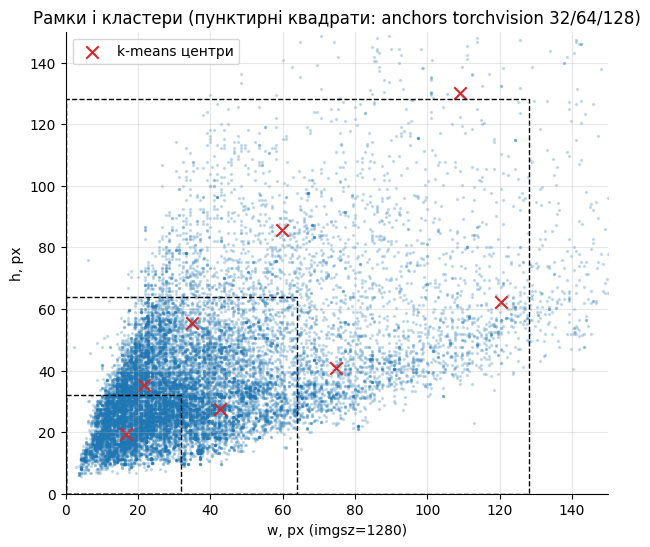

In [53]:
fig, ax = plt.subplots(figsize=(7, 6))
shown = wh[rng.choice(len(wh), min(20_000, len(wh)), replace=False)]
ax.scatter(shown[:, 0], shown[:, 1], s=2, alpha=0.2, color=COLORS[0])
ax.scatter(centers[:, 0], centers[:, 1], s=80, color=COLORS[3], marker="x", label="k-means центри")
for size in (32, 64, 128):
    ax.add_patch(patches.Rectangle((0, 0), size, size, fill=False, ec="k", ls="--", lw=1))
ax.set_xlim(0, 150)
ax.set_ylim(0, 150)
ax.set_xlabel(f"w, px (imgsz={ANCHOR_IMGSZ})")
ax.set_ylabel("h, px")
ax.set_title("Рамки і кластери (пунктирні квадрати: anchors torchvision 32/64/128)")
ax.legend()
plt.show()

## 5. Скільки об'єктів на кадрі

Це важливо через три обмеження: Kaggle рахує до 500 детекцій на кадр, Ultralytics за замовчуванням видає до 300 (`max_det`), а в RT-DETR 300 queries, тобто більше 300 об'єктів він знайти не може.

In [54]:
counts = (
    images.join(per_frame, on=["split", "image_id"], how="left")
    .with_columns(pl.col("n").fill_null(0))
)
counts.group_by("split").agg(
    mean=pl.col("n").mean().round(1),
    median=pl.col("n").median(),
    p95=pl.col("n").quantile(0.95),
    p99=pl.col("n").quantile(0.99),
    max=pl.col("n").max(),
    empty_frames=(pl.col("n") == 0).sum(),
    over_300=(pl.col("n") > 300).sum(),
)

split,mean,median,p95,p99,max,empty_frames,over_300
str,f64,f64,f64,f64,u32,u32,u32
"""train""",45.7,43.0,118.0,142.0,180,3,0
"""val""",40.1,37.0,103.0,113.0,116,0,0


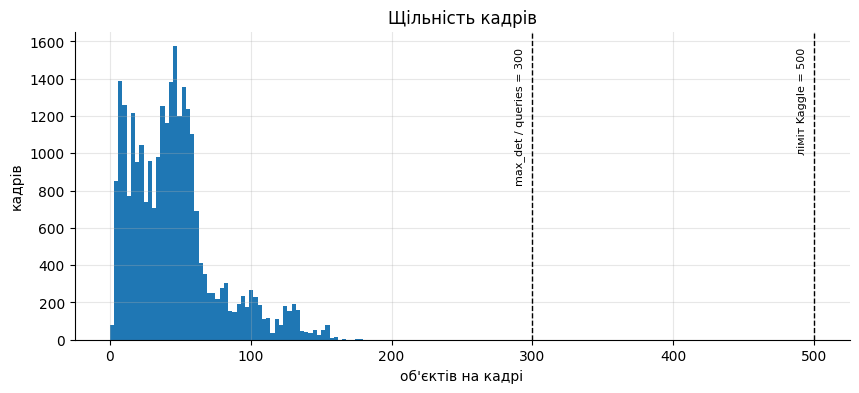

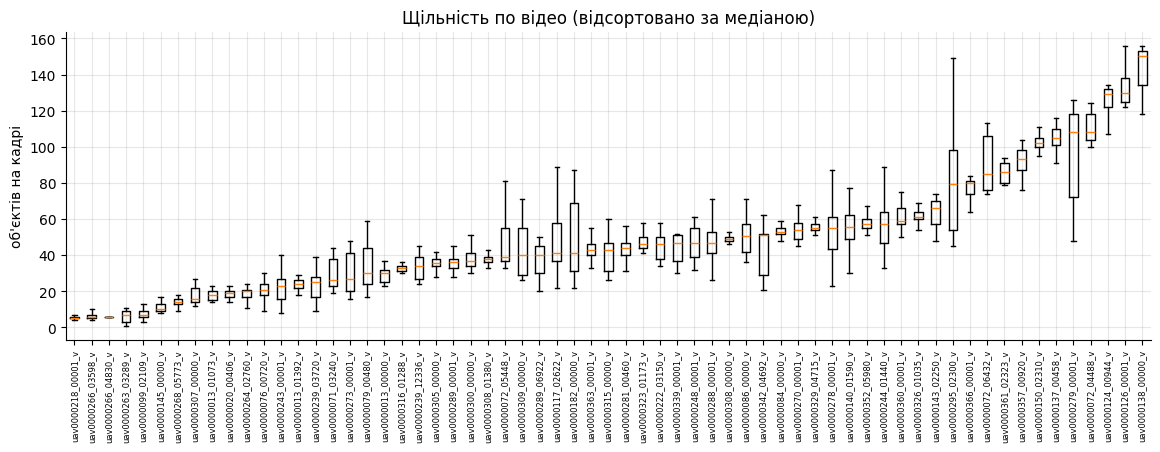

In [55]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(counts["n"], bins=60, color=COLORS[0])
for limit, label in [(300, "max_det / queries = 300"), (500, "ліміт Kaggle = 500")]:
    ax.axvline(limit, color="k", ls="--", lw=1)
    ax.text(limit - 5, ax.get_ylim()[1] * 0.95, label, rotation=90, fontsize=8, ha="right", va="top")
ax.set_xlabel("об'єктів на кадрі")
ax.set_ylabel("кадрів")
ax.set_title("Щільність кадрів")
plt.show()

order = counts.group_by("video").agg(pl.col("n").median()).sort("n")["video"].to_list()
fig, ax = plt.subplots(figsize=(14, 4))
ax.boxplot([counts.filter(pl.col("video") == video)["n"].to_numpy() for video in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order, rotation=90, fontsize=6)
ax.set_ylabel("об'єктів на кадрі")
ax.set_title("Щільність по відео (відсортовано за медіаною)")
plt.show()

## 6. Різниця між відео

Зводимо характеристики кожного відео, щоб зрозуміти, чи нормальний готовий поділ 56/7 і чи схожий val на train. Для test розмітки немає, але є роздільність з `test_images.csv`.

In [56]:
clips = (
    objects.group_by("split", "video")
    .agg(median_side=pl.col("side").median().round(1), small_share=(pl.col("area") < 32**2).mean().round(3))
    .join(counts.group_by("split", "video").agg(frames=pl.len(), mean_objects=pl.col("n").mean().round(1), width=pl.col("width").first(), height=pl.col("height").first()), on=["split", "video"])
    .sort("split", "median_side")
)
clips

split,video,median_side,small_share,frames,mean_objects,width,height
str,str,f64,f64,u32,f64,i64,i64
"""train""","""uav0000239_12336_v""",24.5,0.652,341,33.3,1344,756
"""train""","""uav0000248_00001_v""",30.0,0.731,677,47.5,1344,756
"""train""","""uav0000264_02760_v""",31.0,0.545,616,19.1,1904,1071
"""train""","""uav0000278_00001_v""",31.5,0.511,962,55.0,1360,765
"""train""","""uav0000239_03720_v""",33.3,0.478,680,23.0,1344,756
"""train""","""uav0000279_00001_v""",33.4,0.476,547,95.3,1904,1071
"""train""","""uav0000243_00001_v""",35.2,0.444,768,22.9,1344,756
"""train""","""uav0000099_02109_v""",37.1,0.287,1255,7.1,1344,756
"""train""","""uav0000270_00001_v""",37.5,0.344,680,54.1,1904,1071


In [57]:
test_images = pl.read_csv(ROOT / "test_images.csv")
resolutions = pl.concat(
    [
        clips.select("split", "width", "height"),
        test_images.group_by("clip").agg(pl.col("width").first(), pl.col("height").first()).select(split=pl.lit("test"), width="width", height="height"),
    ],
    how="vertical_relaxed",
)
(
    resolutions.with_columns(resolution=pl.format("{}x{}", "width", "height"))
    .group_by("resolution", "split")
    .agg(clips=pl.len())
    .pivot(on="split", index="resolution", values="clips")
    .fill_null(0)
    .sort("resolution")
)

resolution,train,val,test
str,u32,u32,u32
"""1344x756""",11,2,7
"""1360x764""",0,0,18
"""1360x765""",1,0,0
"""1904x1071""",30,2,0
"""1904x1072""",0,0,4
"""1920x1080""",1,0,11
"""2688x1512""",11,1,0
"""2720x1530""",2,1,0
"""3840x2160""",0,1,0


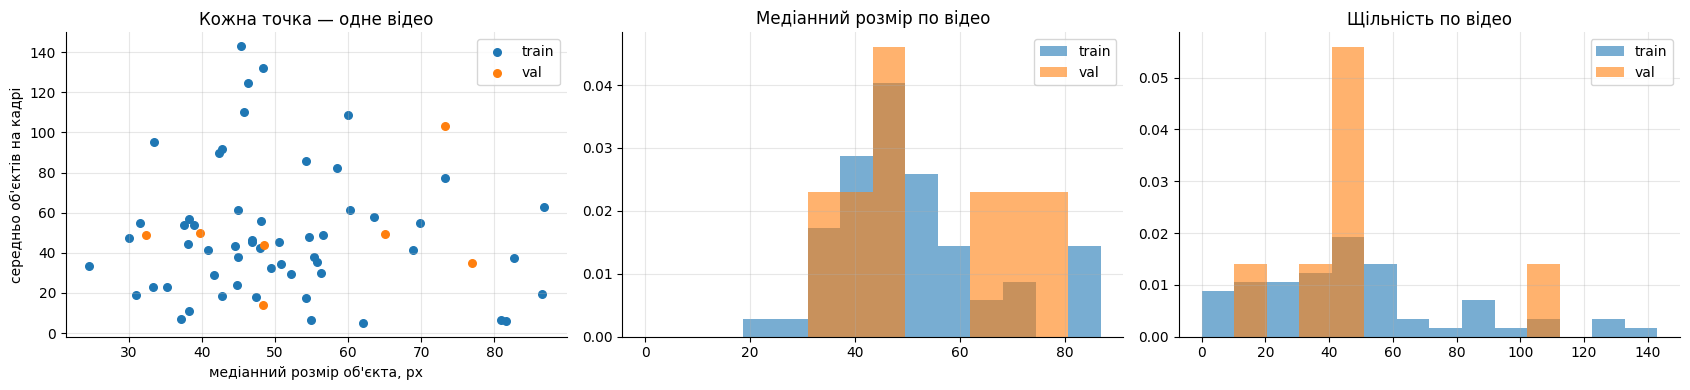

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for split, color in [("train", COLORS[0]), ("val", COLORS[1])]:
    part = clips.filter(pl.col("split") == split)
    axes[0].scatter(part["median_side"], part["mean_objects"], color=color, label=split, s=30)
    axes[1].hist(part["median_side"], bins=np.linspace(0, clips["median_side"].max(), 15), alpha=0.6, color=color, label=split, density=True)
    axes[2].hist(part["mean_objects"], bins=np.linspace(0, clips["mean_objects"].max(), 15), alpha=0.6, color=color, label=split, density=True)
axes[0].set_xlabel("медіанний розмір об'єкта, px")
axes[0].set_ylabel("середньо об'єктів на кадрі")
axes[0].set_title("Кожна точка — одне відео")
axes[1].set_title("Медіанний розмір по відео")
axes[2].set_title("Щільність по відео")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Ignored regions

У цих зонах є об'єкти, але без розмітки. Якщо модель вчити вважати їх фоном, вона почне пропускати справжні об'єкти. Дивимось, наскільки їх багато.

In [59]:
def covered_share(xs, ys, ws, hs, width, height):
    mask = np.zeros((height // 8 + 1, width // 8 + 1), bool)
    for x, y, w, h in zip(xs, ys, ws, hs):
        mask[int(max(y, 0)) // 8:int(y + h) // 8 + 1, int(max(x, 0)) // 8:int(x + w) // 8 + 1] = True
    return float(mask.mean())


grouped = (
    ignore.group_by("split", "image_id")
    .agg(pl.col("x", "y", "w", "h"), pl.col("width").first(), pl.col("height").first(), regions=pl.len())
)
ignore_area = grouped.select("split", "image_id", "regions").with_columns(
    covered=pl.Series([covered_share(*row) for row in grouped.select("x", "y", "w", "h", "width", "height").iter_rows()])
)
(
    images.join(ignore_area, on=["split", "image_id"], how="left")
    .with_columns(pl.col("regions").fill_null(0), pl.col("covered").fill_null(0))
    .group_by("split")
    .agg(
        frames_with_ignore_pct=((pl.col("regions") > 0).mean() * 100).round(1),
        mean_regions=pl.col("regions").mean().round(2),
        mean_covered_pct=(pl.col("covered").mean() * 100).round(2),
        max_covered_pct=(pl.col("covered").max() * 100).round(1),
    )
)

split,frames_with_ignore_pct,mean_regions,mean_covered_pct,max_covered_pct
str,f64,f64,f64,f64
"""train""",74.7,21.1,2.6,38.9
"""val""",50.4,11.23,1.73,10.6


План такий: на тренуванні зафарбовуємо ці зони сірим (114, як паддінг в Ultralytics), а на валідації передаємо їх як `iscrowd = 1`, щоб детекції там не рахувались помилками. Нижче приклад на кадрі, де таких зон найбільше.

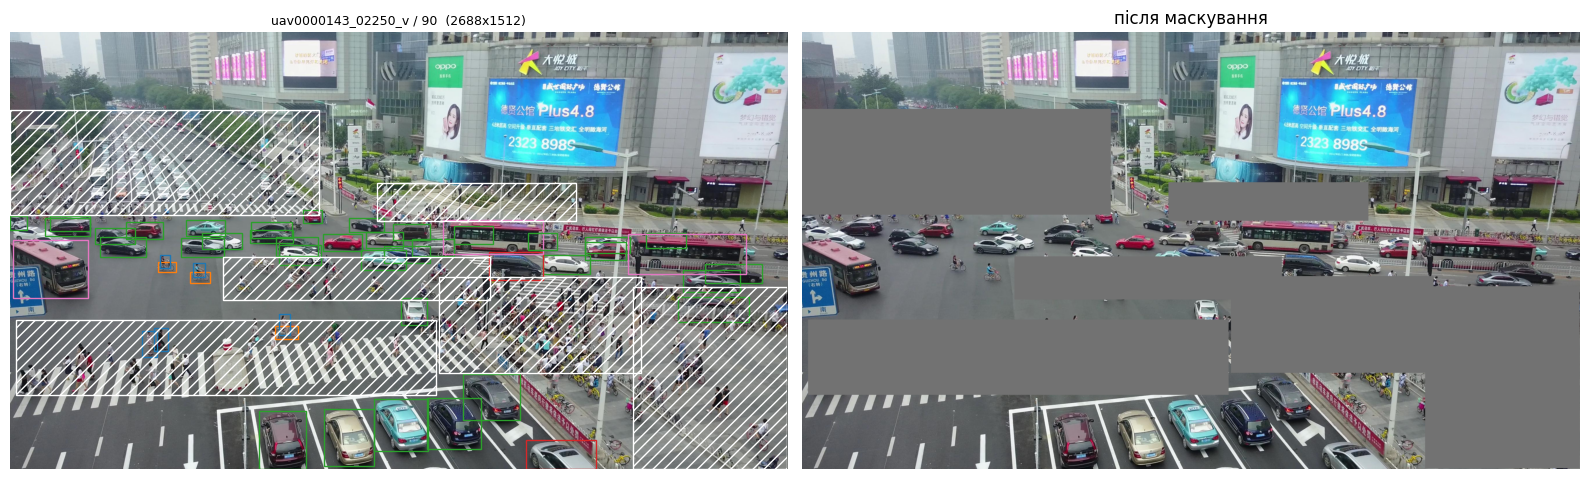

In [60]:
def mask_ignored(image, regions):
    masked = np.array(image).copy()
    for cls, x, y, w, h in regions:
        masked[int(max(y, 0)):int(y + h), int(max(x, 0)):int(x + w)] = 114
    return masked


if ignore.height:
    row = images.join(ignore_area, on=["split", "image_id"]).sort("covered", descending=True).row(0, named=True)
    regions = yolo_to_pixels(Path(frame_path(row["split"], row["file_name"], "ignore", ".txt")), row["width"], row["height"])
    original = Image.open(frame_path(row["split"], row["file_name"]))

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    draw_frame(axes[0], row)
    axes[1].imshow(mask_ignored(original, regions))
    axes[1].set_title("після маскування")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

## 8. Перекриття і обрізаність

`occlusion`: 0 немає, 1 часткове, 2 сильне. `truncation`: об'єкт обрізаний краєм кадру. Це знадобиться потім, коли будемо розбирати помилки моделей.

In [61]:
(
    objects.group_by("name")
    .agg(
        count=pl.len(),
        occluded_pct=((pl.col("occlusion") > 0).mean() * 100).round(1),
        heavy_occlusion_pct=((pl.col("occlusion") == 2).mean() * 100).round(1),
        truncated_pct=((pl.col("truncation") > 0).mean() * 100).round(1),
    )
    .sort("count", descending=True)
)

name,count,occluded_pct,heavy_occlusion_pct,truncated_pct
str,u32,f64,f64,f64
"""car""",537122,43.8,4.9,5.8
"""person""",379013,47.0,6.1,2.2
"""motor""",114844,48.1,6.4,3.3
"""van""",53782,45.1,3.5,5.7
"""tricycle""",46836,58.3,2.6,4.2
"""bicycle""",46277,58.3,3.2,1.0
"""truck""",31857,65.4,15.6,11.3
"""bus""",9917,43.4,2.0,13.7


## 9. Сусідні кадри і крок підвибірки

На одне відео припадають сотні кадрів. Перевіряємо, наскільки сусідні кадри схожі: беремо той самий об'єкт (`track_id`) на кадрі t і на кадрі t+k і рахуємо IoU його рамок.

In [62]:
tracks = objects.filter(pl.col("track_id").is_not_null()).select("split", "video", "track_id", "frame_id", "x", "y", "w", "h")

shifts = []
for step in [1, 2, 3, 5, 10, 15, 20, 30]:
    pairs = tracks.join(
        tracks.with_columns(pl.col("frame_id") - step),
        on=["split", "video", "track_id", "frame_id"],
        suffix="_next",
    )
    overlap_w = (pl.min_horizontal(pl.col("x") + pl.col("w"), pl.col("x_next") + pl.col("w_next")) - pl.max_horizontal("x", "x_next")).clip(lower_bound=0)
    overlap_h = (pl.min_horizontal(pl.col("y") + pl.col("h"), pl.col("y_next") + pl.col("h_next")) - pl.max_horizontal("y", "y_next")).clip(lower_bound=0)
    iou = pairs.select(
        (overlap_w * overlap_h / (pl.col("w") * pl.col("h") + pl.col("w_next") * pl.col("h_next") - overlap_w * overlap_h)).alias("iou")
    )["iou"]
    shifts.append({"step": step, "pairs": pairs.height, "median_iou": round(iou.median(), 3), "iou_below_0.5_pct": round((iou < 0.5).mean() * 100, 1)})

shifts = pl.DataFrame(shifts)
shifts

step,pairs,median_iou,iou_below_0.5_pct
i64,i64,f64,f64
1,1210912,0.895,4.7
2,1202547,0.806,14.8
3,1194217,0.727,25.2
5,1177672,0.591,41.2
10,1137275,0.348,61.2
15,1098412,0.194,69.8
20,1060628,0.093,74.6
30,988664,0.0,79.5


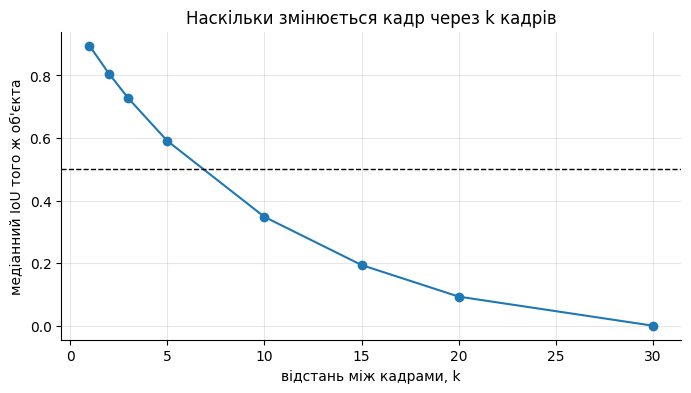

step,train frames
i64,i64
1,24201
2,12114
3,8090
5,4868
10,2446


In [63]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(shifts["step"], shifts["median_iou"], marker="o")
ax.axhline(0.5, color="k", ls="--", lw=1)
ax.set_xlabel("відстань між кадрами, k")
ax.set_ylabel("медіанний IoU того ж об'єкта")
ax.set_title("Наскільки змінюється кадр через k кадрів")
plt.show()

frames_per_clip = images.filter(pl.col("split") == "train").group_by("video").agg(frames=pl.len())
pl.DataFrame([{"step": step, "train frames": int((frames_per_clip["frames"] // step + (frames_per_clip["frames"] % step > 0)).sum())} for step in [1, 2, 3, 5, 10]])

## 10. Додаткові перевірки

### 10.1 Освітлення

У VisDrone є нічні відео. Припущення: вночі об'єктів менше і їх гірше видно. Якщо це так, варто додати аугментацію яскравості. Беремо по 5 кадрів з кожного відео, включно з test, і рахуємо середню яскравість.

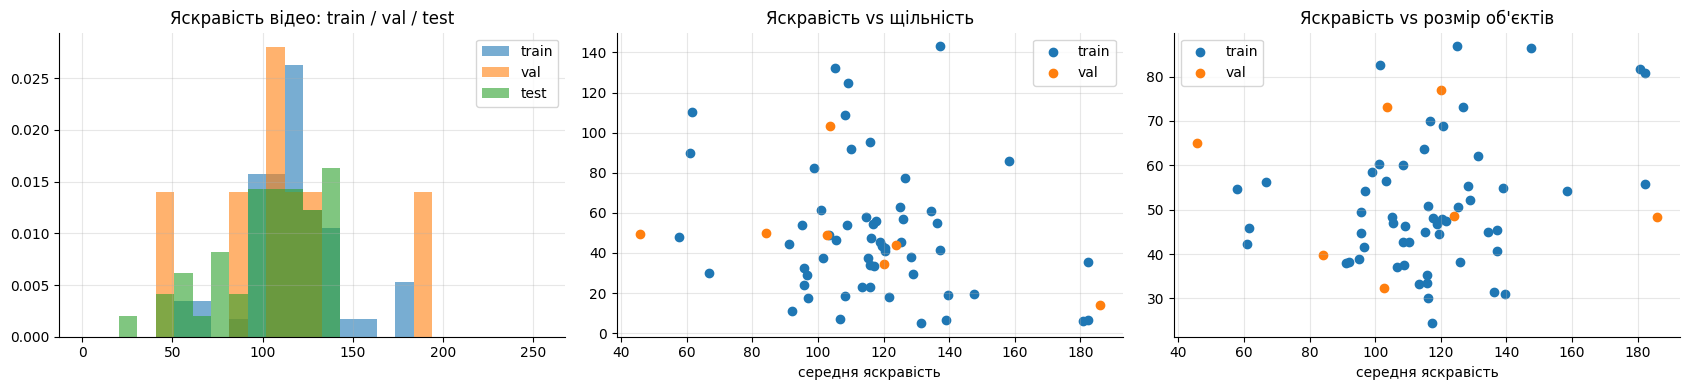

кореляція яскравість ~ щільність: -0.25
кореляція яскравість ~ розмір: 0.21


In [64]:
def brightness(path):
    return float(np.asarray(Image.open(path).convert("L").reduce(8)).mean())


labelled_sample = images.group_by("split", "video").agg(pl.col("file_name").sample(5, with_replacement=True, seed=SEED)).explode("file_name")
light = pl.DataFrame(
    [{"split": split, "video": video, "brightness": brightness(frame_path(split, file_name))} for split, video, file_name in labelled_sample.iter_rows()]
    + [
        {"split": "test", "video": clip, "brightness": brightness(ROOT / file_name)}
        for clip, file_name in test_images.group_by("clip").agg(pl.col("file_name").sample(5, with_replacement=True, seed=SEED)).explode("file_name").iter_rows()
    ]
).group_by("split", "video").agg(pl.col("brightness").mean())

light_clips = clips.join(light, on=["split", "video"])
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for split, color in [("train", COLORS[0]), ("val", COLORS[1]), ("test", COLORS[2])]:
    axes[0].hist(light.filter(pl.col("split") == split)["brightness"], bins=np.linspace(0, 255, 26), alpha=0.6, color=color, label=split, density=True)
for split, color in [("train", COLORS[0]), ("val", COLORS[1])]:
    part = light_clips.filter(pl.col("split") == split)
    axes[1].scatter(part["brightness"], part["mean_objects"], color=color, label=split)
    axes[2].scatter(part["brightness"], part["median_side"], color=color, label=split)
axes[0].set_title("Яскравість відео: train / val / test")
axes[1].set_title("Яскравість vs щільність")
axes[2].set_title("Яскравість vs розмір об'єктів")
axes[1].set_xlabel("середня яскравість")
axes[2].set_xlabel("середня яскравість")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

print("кореляція яскравість ~ щільність:", round(light_clips.select(pl.corr("brightness", "mean_objects")).item(), 2))
print("кореляція яскравість ~ розмір:", round(light_clips.select(pl.corr("brightness", "median_side")).item(), 2))

### 10.2 Де в кадрі об'єкти

Якщо об'єкти зібрані в одній частині кадру, random crop буде часто їх вирізати. Дивимось, де зазвичай центри рамок.

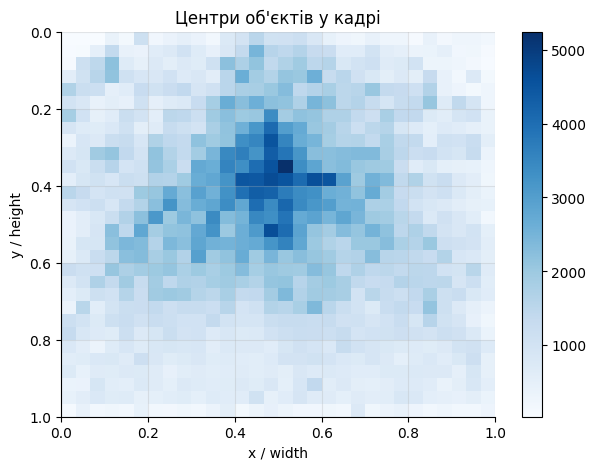

In [65]:
centers_xy = objects.select(((pl.col("x") + pl.col("w") / 2) / pl.col("width")).alias("cx"), ((pl.col("y") + pl.col("h") / 2) / pl.col("height")).alias("cy"))

fig, ax = plt.subplots(figsize=(7, 5))
heat = ax.hist2d(centers_xy["cx"], centers_xy["cy"], bins=30, range=[[0, 1], [0, 1]], cmap="Blues")
ax.invert_yaxis()
ax.set_xlabel("x / width")
ax.set_ylabel("y / height")
ax.set_title("Центри об'єктів у кадрі")
plt.colorbar(heat[3], ax=ax)
plt.show()

## 11. Що зберігаємо

Таблиця кадрів з позначкою, чи кадр іде в тренування. `STEP` беремо з розділу 9. Val не проріджуємо, бо на ньому рахуємо метрики.

In [66]:
STEP = 5

frames = images.with_columns(
    keep=pl.when(pl.col("split") == "val")
    .then(True)
    .otherwise((pl.col("frame_id").rank("ordinal").over("video") - 1) % STEP == 0)
).select("split", "video", "frame_id", "file_name", "width", "height", "keep")

frames.write_parquet(OUT / "frames.parquet")
frames.group_by("split").agg(total=pl.len(), kept=pl.col("keep").sum())

split,total,kept
str,u32,u32
"""train""",24201,4868
"""val""",2846,2846


## 12. Підсумок

| Спостереження | Рішення |
|---|---|
| | |
| | |
| | |